In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import windows
 
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

## Intuition Building with Pure Sine wave

In [16]:
# --- Signal parameters ---
fs = 1000          # Sampling rate in Hz  (samples per second)
T  = 1.0           # Duration in seconds
N  = int(fs * T)   # Total number of samples
 
t = np.linspace(0, T, N, endpoint=False)   # Time axis

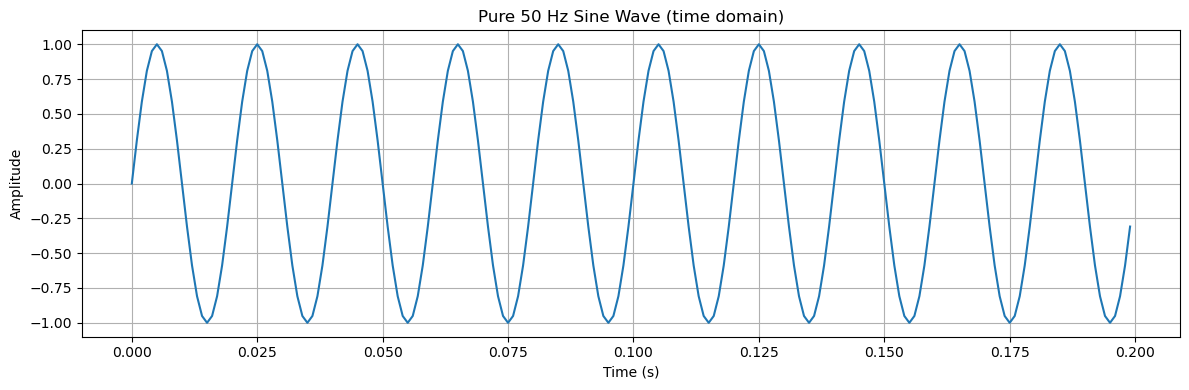

In [17]:
f1 = 50 # Hz
signal_pure = np.sin(2 * np.pi * f1 * t)
 
plt.plot(t[:200], signal_pure[:200])       # Show first 200 ms for clarity
plt.title("Pure 50 Hz Sine Wave (time domain)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

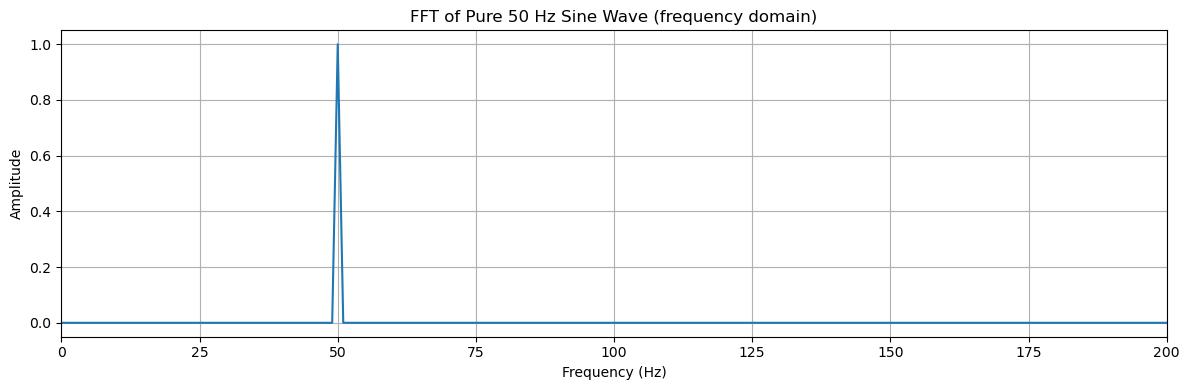

In [18]:
spectrum = fft(signal_pure)
freqs = fftfreq(N, d=1/fs)

# Keep only positive frequencies
pos_mask   = freqs >= 0
freqs_pos  = freqs[pos_mask]
magnitude  = (2 / N) * np.abs(spectrum[pos_mask])   # Normalize so amplitude matches input
 
plt.plot(freqs_pos, magnitude)
plt.title("FFT of Pure 50 Hz Sine Wave (frequency domain)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 200)
plt.tight_layout()
plt.show()

##  Realistic signal with noise

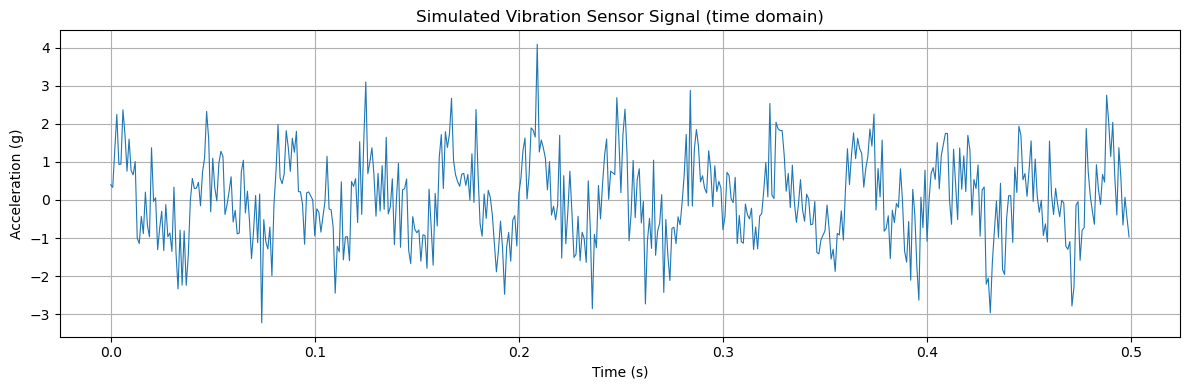

In [19]:
np.random.seed(42)
 
f_fundamental  = 25    # Hz — fundamental (shaft rotation)
f_harmonic     = 50    # Hz — 2nd harmonic (common in imbalance faults)
f_bearing      = 113   # Hz — bearing defect frequency (realistic odd value)
 
signal_sensor = (
    1.0 * np.sin(2 * np.pi * f_fundamental * t) +
    0.5 * np.sin(2 * np.pi * f_harmonic    * t) +
    0.2 * np.sin(2 * np.pi * f_bearing     * t) +
    0.8 * np.random.randn(N)                      # Gaussian noise
)
 
plt.plot(t[:500], signal_sensor[:500], lw=0.8)
plt.title("Simulated Vibration Sensor Signal (time domain)")
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (g)")
plt.tight_layout()
plt.show()

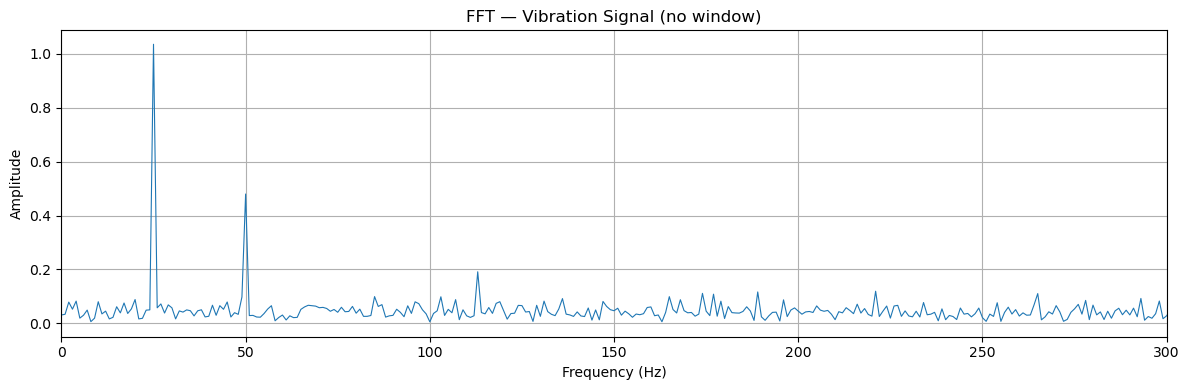

In [20]:
# --- FFT of sensor signal (no windowing) ---
spectrum_sensor = fft(signal_sensor)
magnitude_sensor = (2 / N) * np.abs(spectrum_sensor[pos_mask])
 
plt.plot(freqs_pos, magnitude_sensor, lw=0.8)
plt.title("FFT — Vibration Signal (no window)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 300)
plt.tight_layout()
plt.show()

## Windowing | Peaking Picking

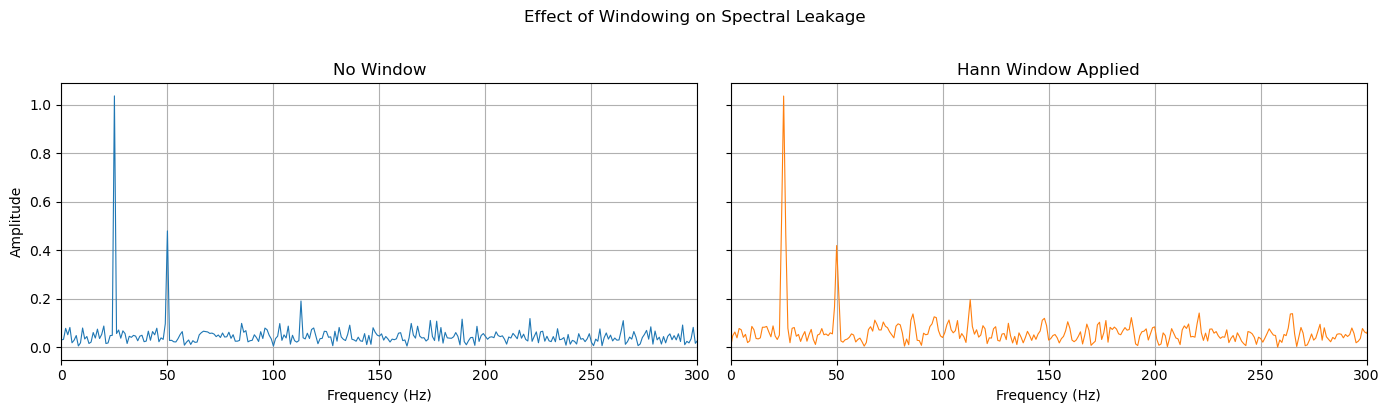

In [21]:
window          = windows.hann(N)
signal_windowed = signal_sensor * window
 
spectrum_win    = fft(signal_windowed)
magnitude_win   = (2 / N) * np.abs(spectrum_win[pos_mask])
 
# Correction factor for Hann window amplitude loss
magnitude_win  *= 2
 
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].plot(freqs_pos, magnitude_sensor, lw=0.8)
axes[0].set_title("No Window")
axes[0].set_xlim(0, 300)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude")
 
axes[1].plot(freqs_pos, magnitude_win, lw=0.8, color="tab:orange")
axes[1].set_title("Hann Window Applied")
axes[1].set_xlim(0, 300)
axes[1].set_xlabel("Frequency (Hz)")
 
plt.suptitle("Effect of Windowing on Spectral Leakage", y=1.02)
plt.tight_layout()
plt.show()

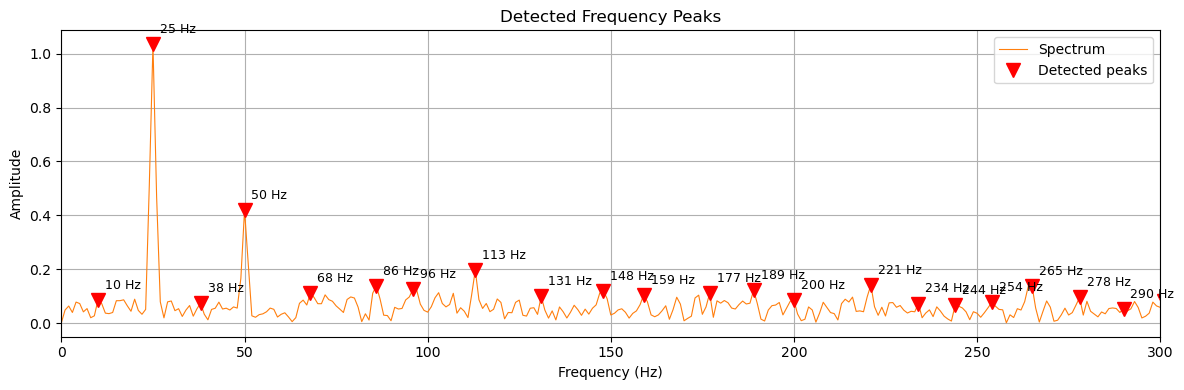

In [23]:
from scipy.signal import find_peaks
 
peaks, props = find_peaks(magnitude_win, height=0.05, distance=10)
 
plt.plot(freqs_pos, magnitude_win, lw=0.8, color="tab:orange", label="Spectrum")
plt.plot(freqs_pos[peaks], magnitude_win[peaks], "rv", ms=10, label="Detected peaks")
 
for pk in peaks:
    plt.annotate(
        f"{freqs_pos[pk]:.0f} Hz",
        xy=(freqs_pos[pk], magnitude_win[pk]),
        xytext=(5, 8), textcoords="offset points", fontsize=9
    )
 
plt.title("Detected Frequency Peaks")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 300)
plt.legend()
plt.tight_layout()
plt.show()